# Dados e Aprendizagem Automática

### Modelação do fluxo de tráfego rodoviário

#### Imports and installations

In [194]:
import sklearn as skl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import shap

from sklearn import linear_model
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import  train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
%matplotlib inline

Load the CSV - *test_data* and *train_data*

In [195]:
df_test = pd.read_csv("/Users/diogo/Desktop/UNI/DAA/Trabalho/DAA-TG/test_data.csv", encoding = "latin1")
df_train = pd.read_csv("/Users/diogo/Desktop/UNI/DAA/Trabalho/DAA-TG/training_data.csv", encoding = "latin1")

#### **Data Exploration and Preparation**

In [196]:
df_train.info

<bound method DataFrame.info of      city_name          record_date AVERAGE_SPEED_DIFF  \
0        Porto  2019-08-29 07:00:00             Medium   
1        Porto  2018-08-10 14:00:00               High   
2        Porto  2019-09-01 16:00:00               High   
3        Porto  2019-02-26 11:00:00               High   
4        Porto  2019-06-06 12:00:00             Medium   
...        ...                  ...                ...   
6807     Porto  2019-02-23 09:00:00                Low   
6808     Porto  2019-06-08 18:00:00             Medium   
6809     Porto  2018-10-02 04:00:00                NaN   
6810     Porto  2019-01-30 01:00:00                NaN   
6811     Porto  2019-06-15 21:00:00             Medium   

      AVERAGE_FREE_FLOW_SPEED  AVERAGE_TIME_DIFF  AVERAGE_FREE_FLOW_TIME  \
0                        41.5               11.5                    71.4   
1                        41.7               48.3                    87.4   
2                        38.6              

In [197]:
df_train.head(10)

,city_name,record_date,AVERAGE_SPEED_DIFF,AVERAGE_FREE_FLOW_SPEED,AVERAGE_TIME_DIFF,AVERAGE_FREE_FLOW_TIME,LUMINOSITY,AVERAGE_TEMPERATURE,AVERAGE_ATMOSP_PRESSURE,AVERAGE_HUMIDITY,AVERAGE_WIND_SPEED,AVERAGE_CLOUDINESS,AVERAGE_PRECIPITATION,AVERAGE_RAIN
0,Porto,2019-08-29 07:00:00,Medium,41.5,11.5,71.4,LIGHT,15.0,1019.0,100.0,3.0,NaN,0.0,NaN
1,Porto,2018-08-10 14:00:00,High,41.7,48.3,87.4,LIGHT,21.0,1021.0,53.0,5.0,céu claro,0.0,NaN
2,Porto,2019-09-01 16:00:00,High,38.6,38.4,85.2,LIGHT,26.0,1014.0,61.0,4.0,NaN,0.0,NaN
3,Porto,2019-02-26 11:00:00,High,37.4,61.0,94.1,LIGHT,18.0,1025.0,48.0,4.0,céu claro,0.0,NaN
4,Porto,2019-06-06 12:00:00,Medium,41.6,50.4,77.0,LIGHT,15.0,1008.0,82.0,10.0,NaN,0.0,NaN
5,Porto,2018-11-15 07:00:00,Medium,52.4,5.6,68.5,LOW_LIGHT,13.0,1014.0,72.0,4.0,nuvens dispersas,0.0,NaN
6,Porto,2018-10-03 21:00:00,NaN,45.7,4.0,79.8,DARK,16.0,1020.0,58.0,0.0,céu claro,0.0,NaN
7,Porto,2018-08-25 19:00:00,Low,40.9,11.8,87.8,LIGHT,19.0,1014.0,64.0,5.0,céu claro,0.0,NaN
8,Porto,2019-06-30 12:00:00,Low,36.4,10.6,72.6,LIGHT,21.0,1019.0,82.0,5.0,céu pouco nublado,0.0,NaN
9,Porto,2019-04-20 09:00:00,Low,34.8,10.1,84.4,LIGHT,19.0,1018.0,55.0,3.0,céu limpo,0.0,NaN


In [198]:
'''
Inspect data
'''
print(df_train.columns)

Index(['city_name', 'record_date', 'AVERAGE_SPEED_DIFF',
       'AVERAGE_FREE_FLOW_SPEED', 'AVERAGE_TIME_DIFF',
       'AVERAGE_FREE_FLOW_TIME', 'LUMINOSITY', 'AVERAGE_TEMPERATURE',
       'AVERAGE_ATMOSP_PRESSURE', 'AVERAGE_HUMIDITY', 'AVERAGE_WIND_SPEED',
       'AVERAGE_CLOUDINESS', 'AVERAGE_PRECIPITATION', 'AVERAGE_RAIN'],
      dtype='object')


In [199]:
df_train.dtypes

city_name                   object
record_date                 object
AVERAGE_SPEED_DIFF          object
AVERAGE_FREE_FLOW_SPEED    float64
AVERAGE_TIME_DIFF          float64
AVERAGE_FREE_FLOW_TIME     float64
LUMINOSITY                  object
AVERAGE_TEMPERATURE        float64
AVERAGE_ATMOSP_PRESSURE    float64
AVERAGE_HUMIDITY           float64
AVERAGE_WIND_SPEED         float64
AVERAGE_CLOUDINESS          object
AVERAGE_PRECIPITATION      float64
AVERAGE_RAIN                object
dtype: object

In [200]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6812 entries, 0 to 6811
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   city_name                6812 non-null   object 
 1   record_date              6812 non-null   object 
 2   AVERAGE_SPEED_DIFF       4612 non-null   object 
 3   AVERAGE_FREE_FLOW_SPEED  6812 non-null   float64
 4   AVERAGE_TIME_DIFF        6812 non-null   float64
 5   AVERAGE_FREE_FLOW_TIME   6812 non-null   float64
 6   LUMINOSITY               6812 non-null   object 
 7   AVERAGE_TEMPERATURE      6812 non-null   float64
 8   AVERAGE_ATMOSP_PRESSURE  6812 non-null   float64
 9   AVERAGE_HUMIDITY         6812 non-null   float64
 10  AVERAGE_WIND_SPEED       6812 non-null   float64
 11  AVERAGE_CLOUDINESS       4130 non-null   object 
 12  AVERAGE_PRECIPITATION    6812 non-null   float64
 13  AVERAGE_RAIN             563 non-null    object 
dtypes: float64(8), object(6)

In [201]:
df_train.describe()

,AVERAGE_FREE_FLOW_SPEED,AVERAGE_TIME_DIFF,AVERAGE_FREE_FLOW_TIME,AVERAGE_TEMPERATURE,AVERAGE_ATMOSP_PRESSURE,AVERAGE_HUMIDITY,AVERAGE_WIND_SPEED,AVERAGE_PRECIPITATION
count,6812.000000,6812.000000,6812.000000,6812.000000,6812.000000,6812.000000,6812.000000,6812.0
mean,40.661010,25.637111,81.143952,16.193482,1017.388139,80.084190,3.058573,0.0
std,4.119023,33.510507,8.294401,5.163492,5.751061,18.238863,2.138421,0.0
min,30.500000,0.000000,46.400000,0.000000,985.000000,14.000000,0.000000,0.0
25%,37.600000,2.275000,75.400000,13.000000,1015.000000,69.750000,1.000000,0.0
50%,40.700000,12.200000,82.400000,16.000000,1017.000000,83.000000,3.000000,0.0
75%,43.500000,36.200000,87.400000,19.000000,1021.000000,93.000000,4.000000,0.0
max,55.900000,296.500000,112.000000,35.000000,1033.000000,100.000000,14.000000,0.0


<Axes: >

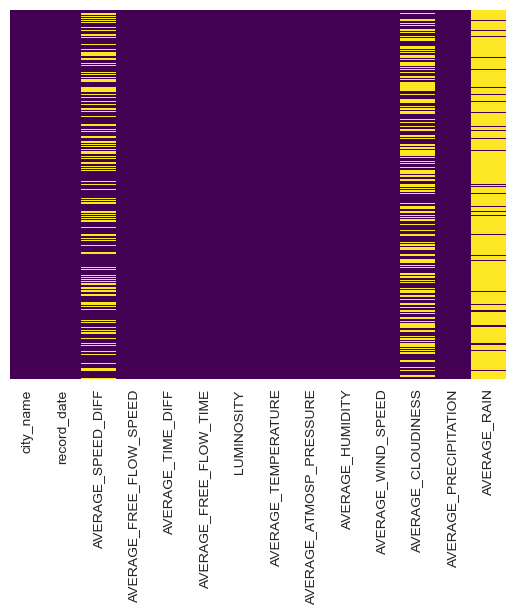

In [202]:
sns.heatmap(df_train.isnull(), yticklabels=False, cbar=False, cmap='viridis')

In [203]:
print(df_train.isna().sum())

city_name                     0
record_date                   0
AVERAGE_SPEED_DIFF         2200
AVERAGE_FREE_FLOW_SPEED       0
AVERAGE_TIME_DIFF             0
AVERAGE_FREE_FLOW_TIME        0
LUMINOSITY                    0
AVERAGE_TEMPERATURE           0
AVERAGE_ATMOSP_PRESSURE       0
AVERAGE_HUMIDITY              0
AVERAGE_WIND_SPEED            0
AVERAGE_CLOUDINESS         2682
AVERAGE_PRECIPITATION         0
AVERAGE_RAIN               6249
dtype: int64


In [204]:
df_train.nunique()

city_name                     1
record_date                6812
AVERAGE_SPEED_DIFF            4
AVERAGE_FREE_FLOW_SPEED     225
AVERAGE_TIME_DIFF          1151
AVERAGE_FREE_FLOW_TIME      442
LUMINOSITY                    3
AVERAGE_TEMPERATURE          38
AVERAGE_ATMOSP_PRESSURE      43
AVERAGE_HUMIDITY             77
AVERAGE_WIND_SPEED           15
AVERAGE_CLOUDINESS            9
AVERAGE_PRECIPITATION         1
AVERAGE_RAIN                 13
dtype: int64

In [205]:
'''
Categorical variables
'''
df_train['AVERAGE_SPEED_DIFF'].value_counts()

AVERAGE_SPEED_DIFF
Medium       1651
Low          1419
High         1063
Very_High     479
Name: count, dtype: int64

In [206]:
df_train['LUMINOSITY'].value_counts()

LUMINOSITY
LIGHT        3293
DARK         3253
LOW_LIGHT     266
Name: count, dtype: int64

In [207]:
df_train['AVERAGE_CLOUDINESS'].value_counts()

AVERAGE_CLOUDINESS
céu claro            1582
céu pouco nublado     516
nuvens dispersas      459
nuvens quebrados      448
algumas nuvens        422
nuvens quebradas      416
céu limpo             153
tempo nublado          67
nublado                67
Name: count, dtype: int64

In [208]:
df_train['AVERAGE_RAIN'].value_counts()

AVERAGE_RAIN
chuva fraca                    261
chuva moderada                 153
chuva leve                      45
aguaceiros fracos               38
chuva                           30
aguaceiros                      11
chuva forte                      8
trovoada com chuva leve          7
chuvisco fraco                   5
chuva de intensidade pesado      2
chuva de intensidade pesada      1
trovoada com chuva               1
chuvisco e chuva fraca           1
Name: count, dtype: int64

In [209]:
df_train['city_name'].value_counts()

city_name
Porto    6812
Name: count, dtype: int64

In [210]:
df_train['AVERAGE_PRECIPITATION'].value_counts()

AVERAGE_PRECIPITATION
0.0    6812
Name: count, dtype: int64

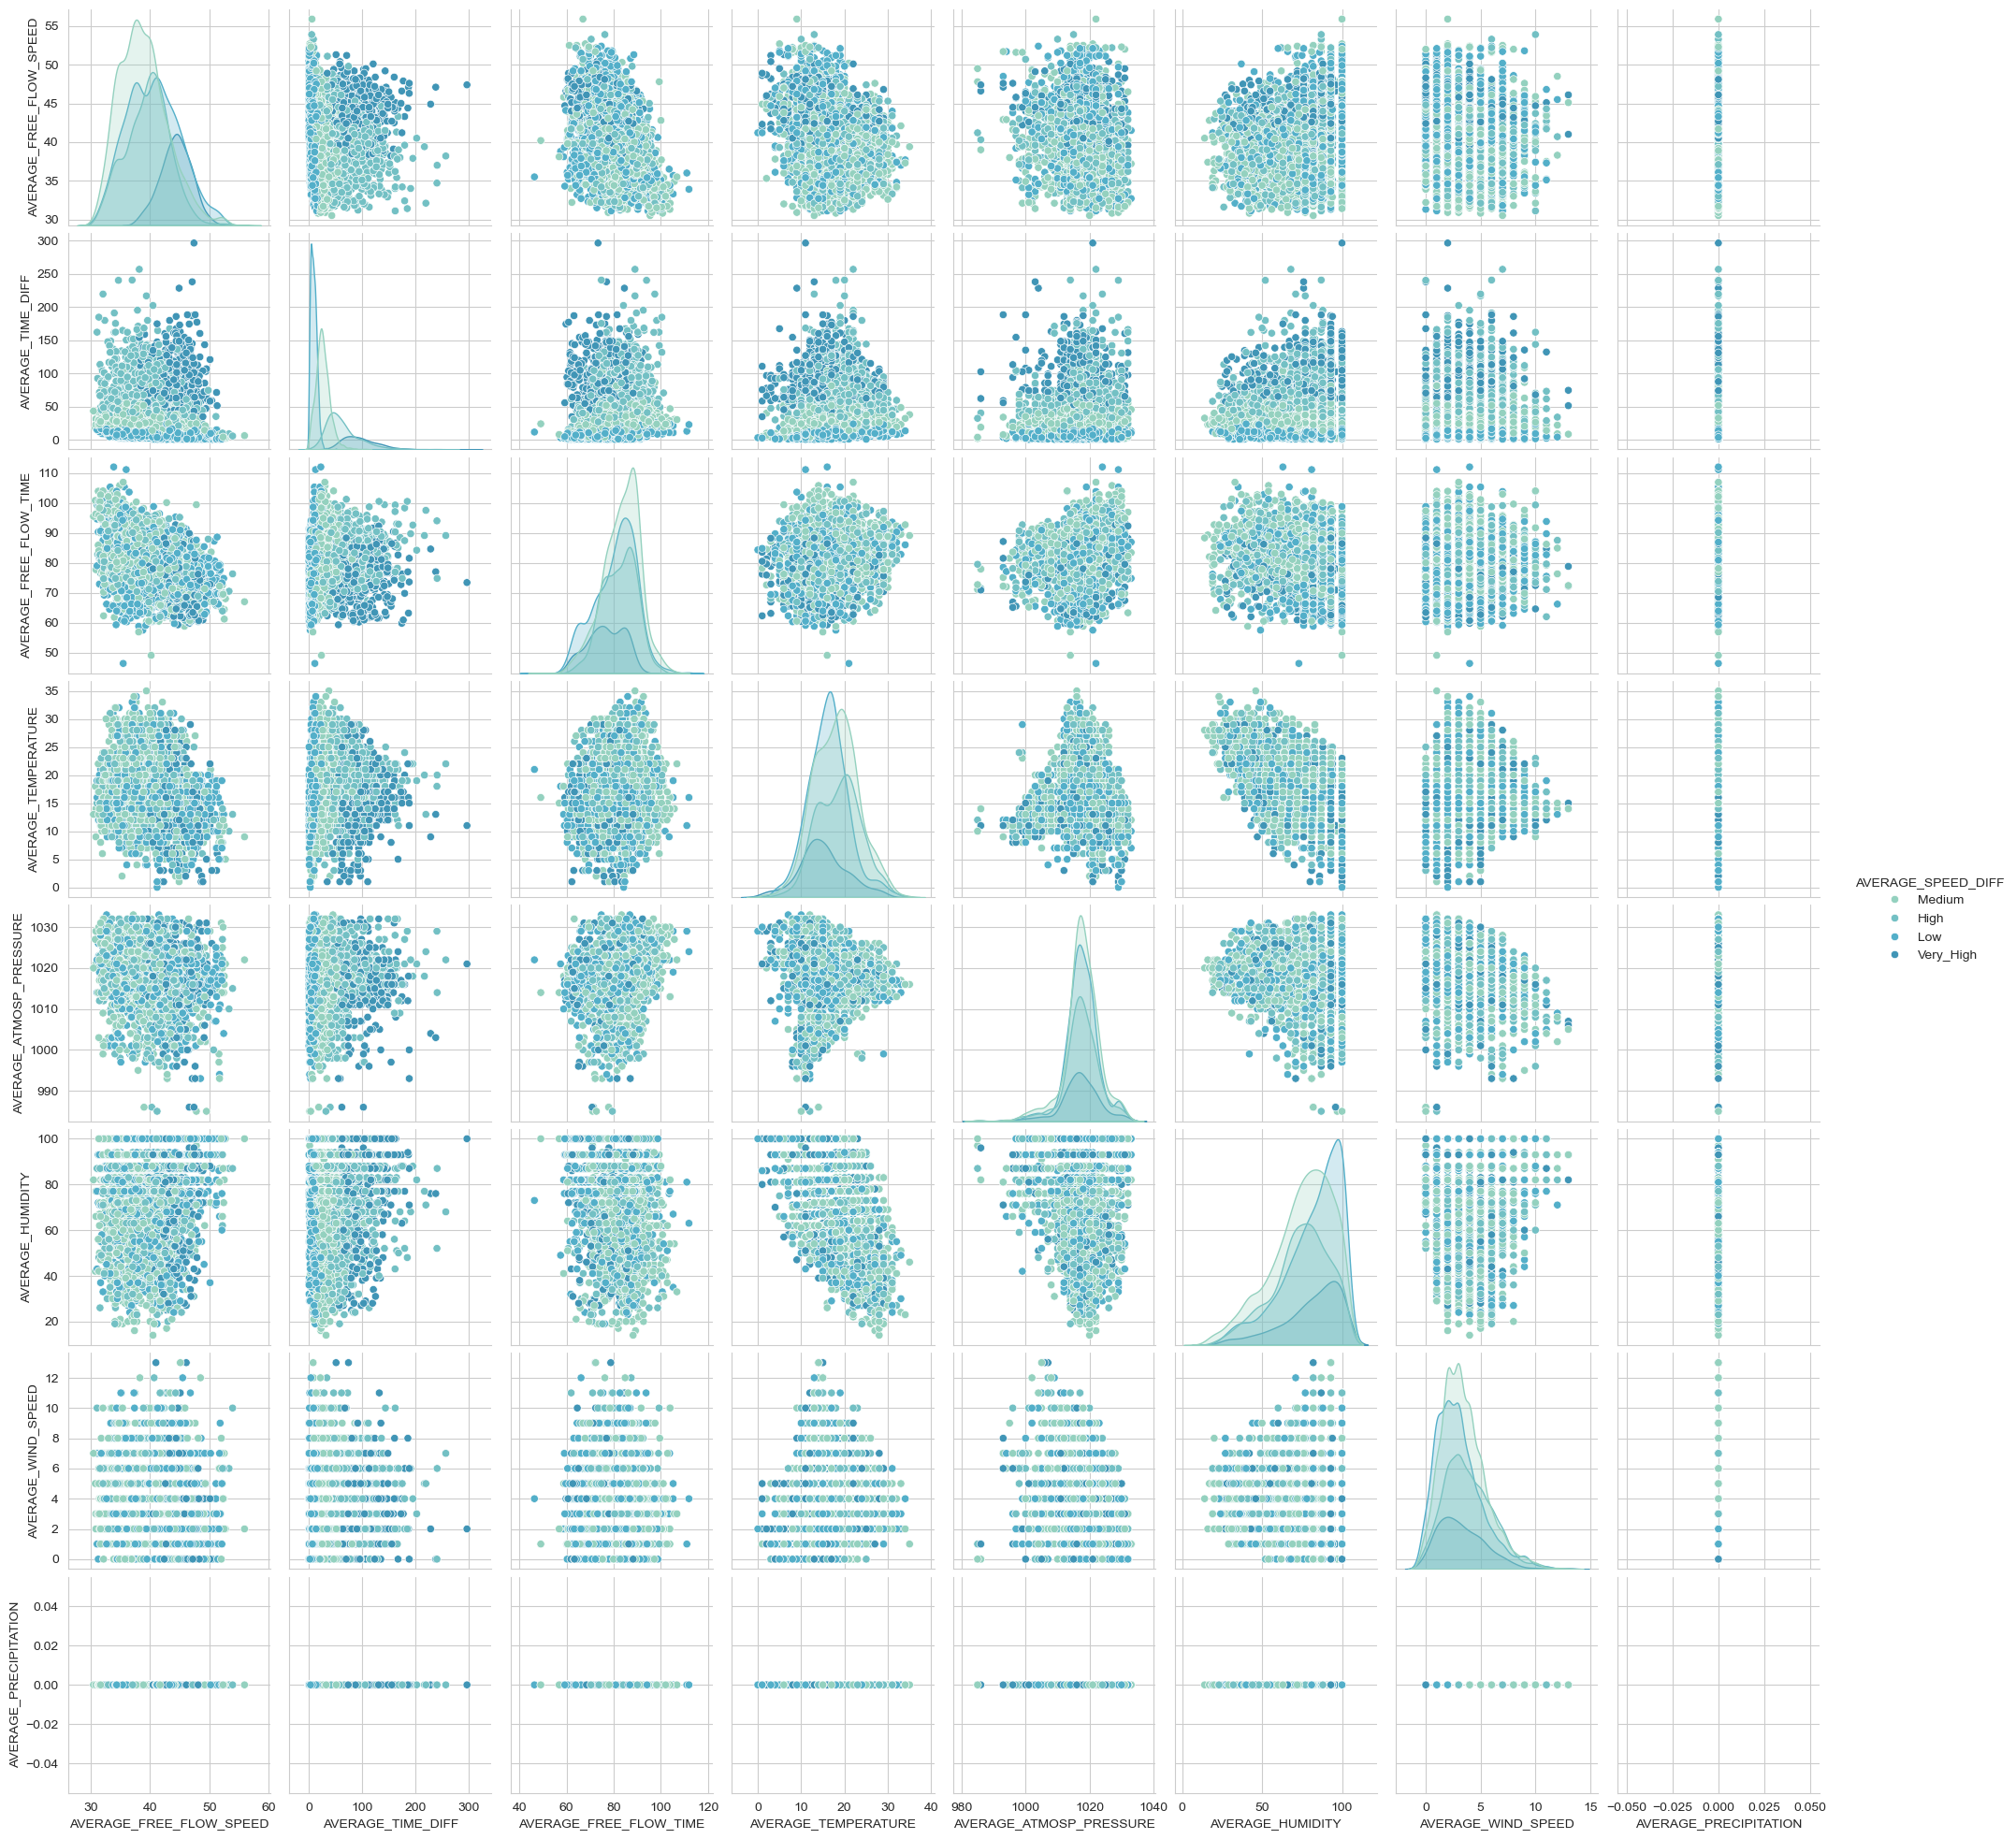

In [211]:
sns.pairplot(df_train, hue = 'AVERAGE_SPEED_DIFF')

<Axes: >

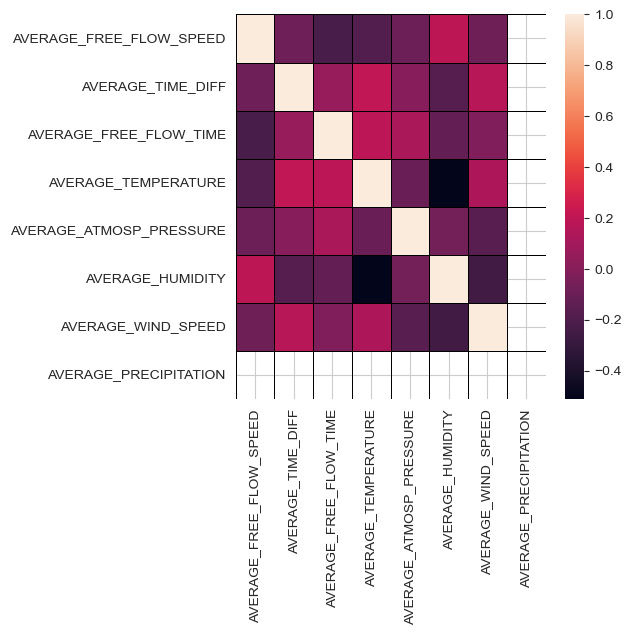

In [212]:
fig = plt.figure(figsize = (5,5))
SpeedDiff_corr = df_train.select_dtypes(include=['number']).corr(method='pearson')
sns.heatmap(SpeedDiff_corr, linecolor='black', linewidths=0.5)

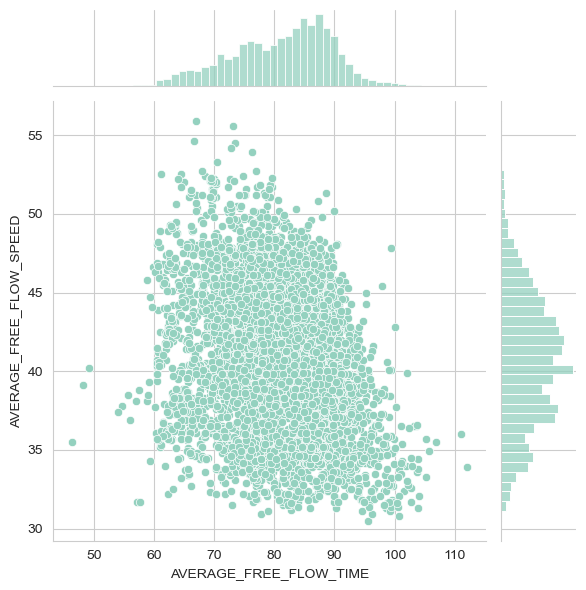

In [213]:
sns.set_palette("GnBu_d")
sns.set_style('whitegrid')
sns.jointplot(x = 'AVERAGE_FREE_FLOW_TIME', y = 'AVERAGE_FREE_FLOW_SPEED' ,data = df_train)

In [214]:
def data_preparation(df):
    df_copy = df.copy()

    cloudiness_map = {
        "céu claro": "Limpo",
        "céu limpo": "Limpo",
    
        "céu pouco nublado": "Parcialmente_Nublado",
        "algumas nuvens": "Parcialmente_Nublado",
        "nuvens dispersas": "Parcialmente_Nublado",
        "nuvens quebrados": "Parcialmente_Nublado",
        "nuvens quebradas": "Parcialmente_Nublado",
    
        "tempo nublado": "Nublado",
        "nublado": "Nublado"
    }

    cloudiness_ordinal = {
        "Limpo": 0,
        "Parcialmente_Nublado": 1,
        "Nublado": 2
    }

    if "AVERAGE_CLOUDINESS" in df_copy.columns:
        df_copy["AVERAGE_CLOUDINESS"] = df_copy["AVERAGE_CLOUDINESS"].replace(cloudiness_map)

        def impute_cloudiness(col):
            cloud = col[0]
            if pd.isnull(cloud):
                return df_copy["AVERAGE_CLOUDINESS"].mode()[0]
            else:
                return cloud

        df_copy["AVERAGE_CLOUDINESS"] = df_copy[["AVERAGE_CLOUDINESS"]].apply(impute_cloudiness, axis=1)
        
        df_copy["AVERAGE_CLOUDINESS"] = df_copy["AVERAGE_CLOUDINESS"].map(cloudiness_ordinal).fillna(1).astype(int)

    if "LUMINOSITY" in df_copy.columns:
        lum_map = {"DARK": 0, "LOW_LIGHT":1, "LIGHT": 2}
        df_copy["LUMINOSITY"] = df_copy["LUMINOSITY"].map(lum_map).fillna(0).astype(int)
    
    df_copy["record_date"] = pd.to_datetime(df_copy["record_date"])
    
    df_copy['record_date_year'] = df_copy['record_date'].dt.year
    df_copy['record_date_month'] = df_copy['record_date'].dt.month
    df_copy['record_date_day'] = df_copy['record_date'].dt.day
    df_copy['record_date_hour'] = df_copy['record_date'].dt.hour
    df_copy["weekday"] = df_copy["record_date"].dt.weekday 
    df_copy["is_weekend"] = (df_copy["weekday"] >= 5).astype(int)

    cols_to_drop = ["city_name", "AVERAGE_RAIN", "AVERAGE_PRECIPITATION", "record_date"]
    df_copy = df_copy.drop(columns=[c for c in cols_to_drop if c in df_copy.columns])

    # Remover colunas extras se existirem
    #cols_to_drop = ["record_date_year","record_date_day"]
    #df_copy = df_copy.drop(columns=[c for c in cols_to_drop if c in df_copy.columns])

    return df_copy

In [217]:
df_train_copy = data_preparation(df_train)
df_train_copy.head()

C:\Users\diogo\AppData\Local\Temp\ipykernel_22196\3762203280.py:28: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  cloud = col[0]


,AVERAGE_SPEED_DIFF,AVERAGE_FREE_FLOW_SPEED,AVERAGE_TIME_DIFF,AVERAGE_FREE_FLOW_TIME,LUMINOSITY,AVERAGE_TEMPERATURE,AVERAGE_ATMOSP_PRESSURE,AVERAGE_HUMIDITY,AVERAGE_WIND_SPEED,AVERAGE_CLOUDINESS,record_date_year,record_date_month,record_date_day,record_date_hour,weekday,is_weekend
0,Medium,41.5,11.5,71.4,2,15.0,1019.0,100.0,3.0,1,2019,8,29,7,3,0
1,High,41.7,48.3,87.4,2,21.0,1021.0,53.0,5.0,0,2018,8,10,14,4,0
2,High,38.6,38.4,85.2,2,26.0,1014.0,61.0,4.0,1,2019,9,1,16,6,1
3,High,37.4,61.0,94.1,2,18.0,1025.0,48.0,4.0,0,2019,2,26,11,1,0
4,Medium,41.6,50.4,77.0,2,15.0,1008.0,82.0,10.0,1,2019,6,6,12,3,0


In [218]:
df_train_copy.nunique()

AVERAGE_SPEED_DIFF            4
AVERAGE_FREE_FLOW_SPEED     225
AVERAGE_TIME_DIFF          1151
AVERAGE_FREE_FLOW_TIME      442
LUMINOSITY                    3
AVERAGE_TEMPERATURE          38
AVERAGE_ATMOSP_PRESSURE      43
AVERAGE_HUMIDITY             77
AVERAGE_WIND_SPEED           15
AVERAGE_CLOUDINESS            3
record_date_year              2
record_date_month            12
record_date_day              31
record_date_hour             24
weekday                       7
is_weekend                    2
dtype: int64

<Axes: >

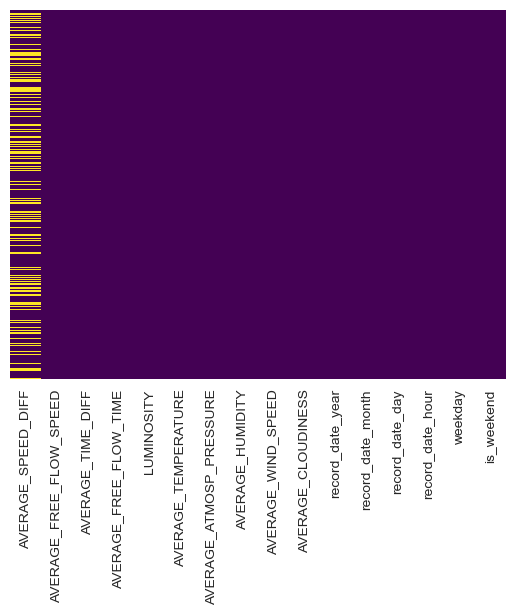

In [219]:
sns.heatmap(df_train_copy.isnull(), yticklabels=False, cbar=False, cmap='viridis')

In [220]:
print(df_train_copy.isna().sum())

AVERAGE_SPEED_DIFF         2200
AVERAGE_FREE_FLOW_SPEED       0
AVERAGE_TIME_DIFF             0
AVERAGE_FREE_FLOW_TIME        0
LUMINOSITY                    0
AVERAGE_TEMPERATURE           0
AVERAGE_ATMOSP_PRESSURE       0
AVERAGE_HUMIDITY              0
AVERAGE_WIND_SPEED            0
AVERAGE_CLOUDINESS            0
record_date_year              0
record_date_month             0
record_date_day               0
record_date_hour              0
weekday                       0
is_weekend                    0
dtype: int64


In [221]:
y_raw = df_train["AVERAGE_SPEED_DIFF"].fillna("None")
train_size = len(df_train)

df_all = pd.concat([df_train.drop("AVERAGE_SPEED_DIFF", axis=1), df_test], ignore_index=True)

df_all_prepared = data_preparation(df_all)

X = df_all_prepared.iloc[:train_size].copy()
df_test_final = df_all_prepared.iloc[train_size:].copy()

mapping = {
    "None": 0,
    "Low": 1,
    "Medium": 2,
    "High": 3,
    "Very_High": 4
}
y = y_raw.map(mapping)

C:\Users\diogo\AppData\Local\Temp\ipykernel_22196\3762203280.py:28: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  cloud = col[0]


In [222]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state =2025)

In [223]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((4768, 15), (4768,), (2044, 15), (2044,))

### Decision Tree

In [225]:
dt_model = DecisionTreeClassifier(random_state = 2025)
dt_model.fit(X_train, y_train)


,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,2025
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [226]:
dt_score = dt_model.score(X_test, y_test)
print("Accuracy: %.2f%%" % (dt_score * 100))
dt_predictions = dt_model.predict(X_test)
print(classification_report(y_test, dt_predictions))

Accuracy: 72.85%
              precision    recall  f1-score   support

           0       0.87      0.86      0.87       640
           1       0.60      0.65      0.62       408
           2       0.71      0.65      0.68       525
           3       0.66      0.69      0.67       337
           4       0.73      0.75      0.74       134

    accuracy                           0.73      2044
   macro avg       0.71      0.72      0.72      2044
weighted avg       0.73      0.73      0.73      2044



In [227]:
results = {}
results['DT'] = dt_score

### Logistic Regression

In [228]:
from sklearn.linear_model import LogisticRegression

In [229]:
lr_model = LogisticRegression(random_state= 2025)

In [230]:
lr_model.fit(X_train, y_train)

C:\Users\diogo\anaconda3\envs\DAA\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,2025
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [231]:
lr_score = lr_model.score(X_test, y_test)

In [232]:
print("Accuracy: %.2f%%" % (lr_score * 100))

Accuracy: 73.63%


In [233]:
results['LR'] = lr_score

### Max Voting

In [234]:
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import cross_val_score

In [235]:
hvt_model = VotingClassifier(estimators = [('dt', dt_model), ('rf', rf_model), ('xgb', xgb_model)], voting = 'hard', weights = [2,1,2])

In [236]:
hvt_model.fit(X_train, y_train)

,estimators,"[('dt', ...), ('rf', ...), ...]"
,voting,'hard'
,weights,"[2, 1, ...]"
,n_jobs,None
,flatten_transform,True
,verbose,False
,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1


In [237]:
for model, label in zip([dt_model, rf_model, xgb_model, hvt_model], ['dt', 'rf', 'xgb', 'Ensemble']):
    hvt_score = cross_val_score(model, X_test, y_test, scoring = 'accuracy', cv= 5)
    print("Accuracy: %0.2f (+- %0.2f) [%s]" % (hvt_score.mean(), hvt_score.std(), label))

Accuracy: 0.71 (+- 0.02) [dt]
Accuracy: 0.78 (+- 0.02) [rf]
Accuracy: 0.80 (+- 0.02) [xgb]
Accuracy: 0.80 (+- 0.01) [Ensemble]


In [238]:
hvt_score = hvt_model.score(X_test, y_test)

In [239]:
print("Accuracy: %.2f%%" % (hvt_score * 100))

Accuracy: 80.92%


In [240]:
hvt_predictions = hvt_model.predict(X_test)

In [241]:
print(classification_report(y_test, hvt_predictions))

              precision    recall  f1-score   support

           0       0.87      0.90      0.89       640
           1       0.68      0.73      0.70       408
           2       0.83      0.78      0.81       525
           3       0.81      0.77      0.79       337
           4       0.84      0.81      0.82       134

    accuracy                           0.81      2044
   macro avg       0.81      0.80      0.80      2044
weighted avg       0.81      0.81      0.81      2044



In [242]:
results['HVT'] = hvt_score

### StratifiedShuffleSplit

In [98]:
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.ensemble import BaggingClassifier

In [99]:
sss = StratifiedShuffleSplit(random_state = 2025)

In [100]:
bg_dt_model = BaggingClassifier(estimator = dt_model, bootstrap = True)

In [101]:
n_estimators = [10,40,60,80]

In [102]:
parameters = {'n_estimators': n_estimators}

In [103]:
grid_bg = GridSearchCV(estimator = bg_dt_model, param_grid = parameters, cv = sss)

In [104]:
grid_bg.fit(X_train, y_train)

,estimator,BaggingClassi...m_state=2025))
,param_grid,"{'n_estimators': [10, 40, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,StratifiedShu...ain_size=None)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [105]:
bst_bg_model = grid_bg.best_estimator_

In [106]:
print(bst_bg_model)

BaggingClassifier(estimator=DecisionTreeClassifier(random_state=2025),
                  n_estimators=60)


In [107]:
bst_bg_model.fit(X_train, y_train)

,estimator,DecisionTreeC...om_state=2025)
,n_estimators,60
,max_samples,1.0
,max_features,1.0
,bootstrap,True
,bootstrap_features,False
,oob_score,False
,warm_start,False
,n_jobs,None
,random_state,None
,verbose,0


In [108]:
bst_bg_score = bst_bg_model.score(X_test, y_test)

In [109]:
print("Accuracy: %.2f%%" % (bst_bg_score * 100))

Accuracy: 79.89%


In [131]:
results['BaggDT'] = bst_bg_score

### Bagging com RF

In [243]:
bg_rf_model = RandomForestClassifier(random_state = 2025)

In [244]:
bg_rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [245]:
bg_rf_score = bg_rf_model.score(X_test, y_test)

In [246]:
print("Accuracy: %.2f%%" % (bg_rf_score * 100))

Accuracy: 78.86%


In [247]:
results['BaggRF'] = bg_rf_score

### Gradient Boosting

In [248]:
from sklearn.ensemble import GradientBoostingClassifier

In [249]:
gbc_model = GradientBoostingClassifier(random_state = 2025)

In [250]:
gbc_model.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [251]:
gbc_score = gbc_model.score(X_test, y_test)

In [252]:
print("Accuracy: %.2f%%" % (gbc_score * 100))

Accuracy: 80.43%


In [253]:
results['GB'] = gbc_score

### Random Forest

In [254]:
rf_model = RandomForestClassifier(random_state= 2025)

In [255]:
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [256]:
rf_score = rf_model.score(X_test, y_test)

In [257]:
print("Accuracy: %.2f%%" % (rf_score * 100))

Accuracy: 78.86%


In [258]:
rf_predictions = rf_model.predict(X_test)

In [259]:
print(classification_report(y_test, rf_predictions))

              precision    recall  f1-score   support

           0       0.84      0.90      0.87       640
           1       0.66      0.66      0.66       408
           2       0.80      0.78      0.79       525
           3       0.79      0.75      0.77       337
           4       0.86      0.76      0.81       134

    accuracy                           0.79      2044
   macro avg       0.79      0.77      0.78      2044
weighted avg       0.79      0.79      0.79      2044



In [260]:
results['RF'] = rf_score

### XGBoost

<code>xgboost.sklearn.XGBClassifier(base_score=None, booster=None, callbacks=None, colsample_bylevel=None, colsample_bynode=None,colsample_bytree=None, device=None, early_stopping_rounds=None,enable_categorical=False, eval_metric=None, feature_types=None,gamma=None, grow_policy=None, importance_type=None,interaction_constraints=None, learning_rate=None, max_bin=None,max_cat_threshold=None, max_cat_to_onehot=None,max_delta_step=None, max_depth=None, max_leaves=None, min_child_weight=None, missing=nan, monotone_constraints=None,multi_strategy=None, n_estimators=None, n_jobs=None,num_parallel_tree=None, random_state=None, ...)</code>

In [261]:
xgb_model = XGBClassifier(colsample_bytree= 0.7, learning_rate= 0.05, max_depth= 5, n_estimators= 200, subsample= 0.8)

In [262]:
xgb_model.fit(X_train, y_train)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.7
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [263]:
xgb_score = xgb_model.score(X_test, y_test)

In [264]:
print("Accuracy: %.2f%%" % (xgb_score * 100))

Accuracy: 81.41%


In [265]:
xgb_predictions = xgb_model.predict(X_test)

In [266]:
print(classification_report(y_test, xgb_predictions))

              precision    recall  f1-score   support

           0       0.88      0.90      0.89       640
           1       0.68      0.74      0.71       408
           2       0.84      0.78      0.81       525
           3       0.81      0.78      0.80       337
           4       0.84      0.82      0.83       134

    accuracy                           0.81      2044
   macro avg       0.81      0.81      0.81      2044
weighted avg       0.82      0.81      0.81      2044



In [156]:
results['XGB'] = xgb_score

## Model Accuracy Comparison

In [164]:
results

{'DT': 0.7284735812133072,
 'LR': 0.7363013698630136,
 'HVT': 0.7989236790606654,
 'BaggDT': 0.7989236790606654,
 'BaggRF': 0.7886497064579256,
 'RF': 0.7886497064579256,
 'XGB': 0.799412915851272,
 'GB': 0.8043052837573386}

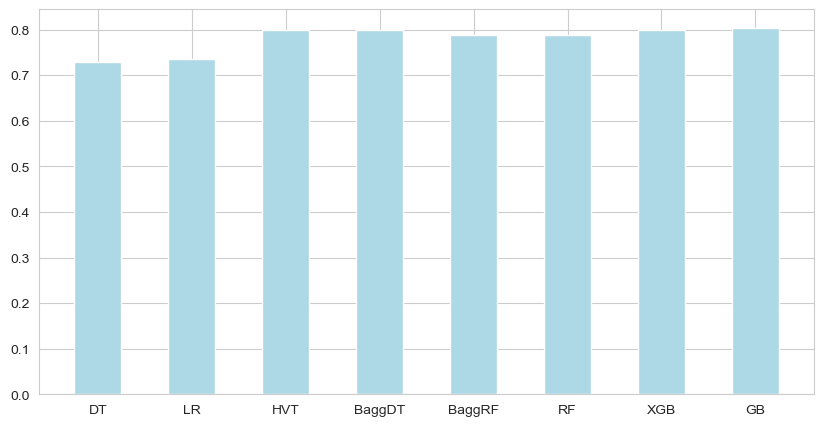

In [165]:
fig = plt.figure(figsize= (10,5))

mod = list(results.keys())
acc = list(results.values())

plt.bar(mod, acc, color = 'lightblue', width = 0.5)
plt.xlabel = 'Model'
plt.ylabel = 'Accuracy'
plt.title = 'Models Accuracy Comparison'
plt.show()

In [41]:
param_grid = {
    'n_estimators': [100, 200, 300, 400, 500, 700],
    'learning_rate': [0.05, 0.1, 0.15, 0.2],
    'max_depth': [4, 5, 7, 9],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0]
}

In [42]:
# Configurar o Grid Search (5-fold Cross-Validation)
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring='accuracy',  
    cv=5,                
    verbose=3,           
    n_jobs=-1            
)

In [44]:
grid_search.fit(X_train, y_train) 

print("\n--- RESULTADOS DO GRID SEARCH ---")
print("Melhor Score de Accuracy (Média CV):", grid_search.best_score_)
print("Melhores Parâmetros Encontrados:", grid_search.best_params_)

Fitting 5 folds for each of 108 candidates, totalling 540 fits

--- RESULTADOS DO GRID SEARCH ---
Melhor Score de Accuracy (Média CV): 0.7992841759774385
Melhores Parâmetros Encontrados: {'colsample_bytree': 0.7, 'learning_rate': 0.05, 'max_depth': 9, 'n_estimators': 300, 'subsample': 0.8}


In [267]:
preds_test = xgb_model.predict(df_test_final)

In [268]:
inverse_mapping = {
    0: "None",
    1: "Low",
    2: "Medium",
    3: "High",
    4: "Very_High"
}

preds_test_labels = pd.Series(preds_test).map(inverse_mapping)

In [269]:
preds_test_labels

0            None
1             Low
2            None
3            High
4             Low
          ...    
1495          Low
1496         None
1497         None
1498    Very_High
1499          Low
Length: 1500, dtype: object

In [270]:
df_test_final.index = range(1, len(df_test) + 1)

In [271]:
submission = pd.DataFrame({
    "RowId": df_test_final.index,
    "Speed_Diff": preds_test_labels
})

submission.to_csv("submission.csv", index=False)

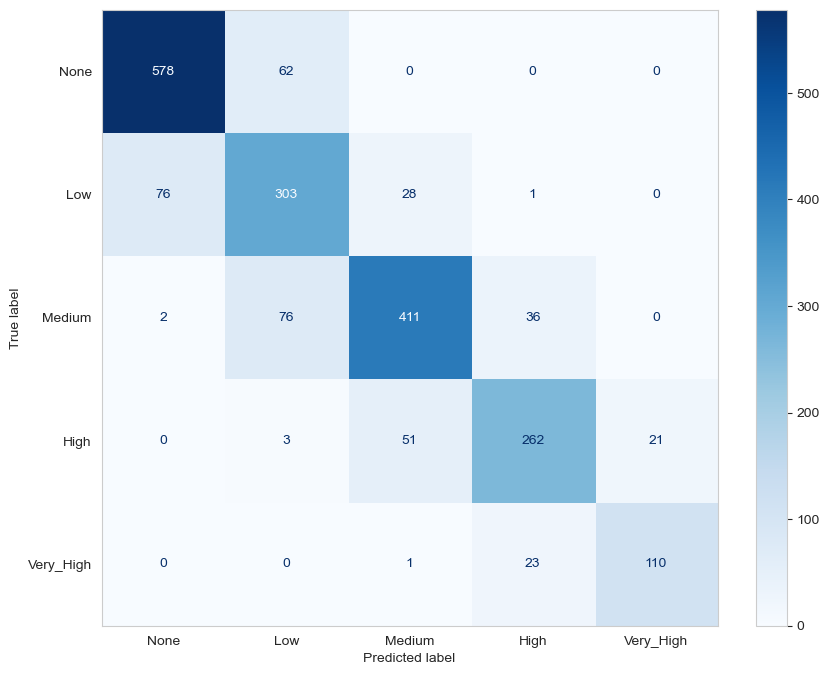

In [273]:
cm = confusion_matrix(y_test, xgb_predictions)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
                              display_labels=["None", "Low", "Medium", "High", "Very_High"])

disp.plot(cmap='Blues', values_format='d', ax=ax)

plt.grid(False)

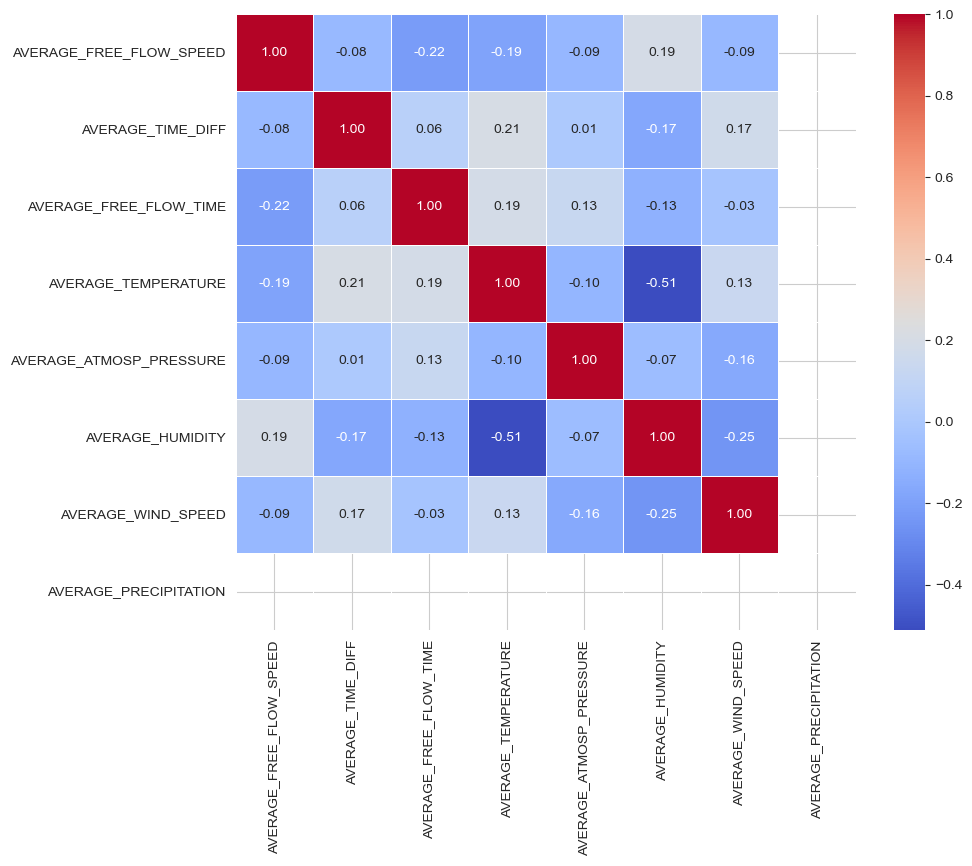

In [277]:
df2 = df_train.drop(['city_name', 'record_date', 'AVERAGE_SPEED_DIFF', 'LUMINOSITY', 'AVERAGE_CLOUDINESS', 'AVERAGE_RAIN'], axis = 1)
correlation_matrix = df2.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.show()

In [94]:
correlation_matrix = df_test_final.corr()
correlation_with_target = correlation_matrix['AVERAGE_SPEED_DIFF'].sort_values(ascending=False)
print("Correlation with target (AVERAGE_SPEED_DIFF):\n", correlation_with_target)

Correlation with target (AVERAGE_SPEED_DIFF):
 AVERAGE_SPEED_DIFF          1.000000
AVERAGE_TIME_DIFF           0.814728
lum_LIGHT                   0.582968
record_date_hour            0.285956
AVERAGE_TEMPERATURE         0.258776
AVERAGE_WIND_SPEED          0.209477
Ceu_Parcialmente_Nublado    0.096040
record_date_year            0.083235
lum_LOW_LIGHT               0.039399
AVERAGE_FREE_FLOW_TIME      0.024276
record_date_day             0.013075
record_date_month          -0.005785
Ceu_Nublado                -0.014278
AVERAGE_ATMOSP_PRESSURE    -0.016710
Ceu_Encoberto              -0.046656
Ceu_Limpo                  -0.057693
AVERAGE_FREE_FLOW_SPEED    -0.076346
weekday                    -0.129614
is_weekend                 -0.197382
AVERAGE_HUMIDITY           -0.224832
lum_DARK                   -0.598516
Name: AVERAGE_SPEED_DIFF, dtype: float64
